# Part G: Regression-Based Prediction of the Number of Violations
**Project:** Food Safety and Restaurant Inspection Analytics &nbsp;|&nbsp; **Student:** Rushikesh Maddewad &nbsp;|&nbsp; PRN 202502040037 &nbsp;|&nbsp; Roll No 353

**Prediction problem:** predict the number of violations recorded in an inspection (**ViolationCount**) from the establishment, risk, inspection type, temporal, area and prior-history features.

**Data lineage:** Raw data > profiling > curation > staging > dimensional warehouse > analytical mart `mart.food_inspection_analytics_mart` > this notebook. The mart is generated from the warehouse (`sql/08_analytics_mart.sql`), not rebuilt from the raw file.

In [1]:
import sys
sys.path.insert(0, "../etl")
from config import connect
import numpy as np, pandas as pd, psycopg2
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
conn = connect()
cur = conn.cursor(); cur.execute("SELECT * FROM mart.food_inspection_analytics_mart")
mart = pd.DataFrame(cur.fetchall(), columns=[c.name for c in cur.description])
mart["violation_count"] = pd.to_numeric(mart["violation_count"])
print("Mart rows:", f"{len(mart):,}", "| columns:", len(mart.columns))
mart[["inspection_date", "facility_type", "risk_category", "inspection_type", "result_group", "violation_count", "prior_inspection_result", "prior_violation_count", "zip", "area"]].head()

Mart rows: 61,737 | columns: 29


,inspection_date,facility_type,risk_category,inspection_type,result_group,violation_count,prior_inspection_result,prior_violation_count,zip,area
0,2022-04-08,Grocery Store,Risk 1 (High),Complaint,Pass,5.0,None,NaN,60649,Southeast
1,2022-08-25,Grocery Store,Risk 1 (High),Complaint,Pass,3.0,Pass,5.0,60649,Southeast
2,2022-11-07,Grocery Store,Risk 1 (High),Short Form Complaint,Pass,3.0,Pass,3.0,60649,Southeast
3,2023-02-21,Grocery Store,Risk 1 (High),Complaint,Pass,4.0,Pass,3.0,60649,Southeast
4,2023-12-01,Grocery Store,Risk 1 (High),Complaint,Conditional Pass,6.0,Pass,4.0,60649,Southeast


## 1. Target, predictors and leakage control
* **Target:** `violation_count`, available for **61,185** completed inspections. The 552 *Fail* / *Pass w/ Conditions* inspections without violation text have an unknown count (NULL) and are excluded from this model.
* **Predictors:** FacilityType, RiskCategory, InspectionType, Month, DayOfWeek, ZIP, PriorInspectionResult, PriorViolationCount.
* **Not used as predictors:** the current inspection's *result*, *ViolationBand*, *HighViolationFlag* and *IsFailedInspection*. They are known only after the inspection and are calculated from (or decided together with) the target, so using them would be data leakage.
* **Prior-history features** come only from a **strictly earlier** inspection of the same licensed facility (`sql/08_analytics_mart.sql`). When there is no earlier inspection in the 2022-2025 data, the prior result is `None` and the prior count is set to 0. The history starts in January 2022, so early inspections look like first visits even if the facility was inspected before 2022.
* `has_prior_inspection` is not a separate predictor: it is identical to `PriorInspectionResult != None` and would be perfectly collinear.

In [2]:
df = mart[mart["violation_count"].notna()].copy()
df["month"] = df["month"].astype(str)
df["prior_violation_count"] = df["prior_violation_count"].astype(float).fillna(0)
df["inspection_date"] = pd.to_datetime(df["inspection_date"])
CAT = ["facility_type", "risk_category", "inspection_type", "month", "day_of_week", "zip", "prior_inspection_result"]
NUM = ["prior_violation_count"]

# chronological split: train 2022-2024, test 2025 (no shuffling, no future data in training)
train = df[df["inspection_date"] < "2025-01-01"]; test = df[df["inspection_date"] >= "2025-01-01"]
print("Train:", len(train), "inspections (2022-2024) | Test:", len(test), "inspections (2025)")
print("Mean violations: train %.3f | test %.3f" % (train["violation_count"].mean(), test["violation_count"].mean()))
print("Share of inspections with a prior inspection: train %.1f%% | test %.1f%%" % (100 * (train["prior_inspection_result"] != "None").mean(), 100 * (test["prior_inspection_result"] != "None").mean()))

Train: 45266 inspections (2022-2024) | Test: 15919 inspections (2025)
Mean violations: train 3.850 | test 3.558
Share of inspections with a prior inspection: train 67.2% | test 87.8%


## 2. Feature engineering and categorical encoding
* **One-hot encoding** for all categorical predictors, because they have no natural order. `drop="first"` removes the redundant dummy (dummy-variable trap).
* **Rare categories** (fewer than 100 training rows) are grouped into one *infrequent* category (`min_frequency=100`). This matters for facility type (about 200 spellings) and ZIP (about 100 codes) and keeps the model stable.
* ViolationCount is a count with a long right tail (see EDA). Ordinary least squares is used as the project document requires; the effect of the tail is examined in the outlier section.

Simple linear regression: ViolationCount = 2.737 + 0.209 x PriorViolationCount   (trained on 30436 inspections with a prior inspection)


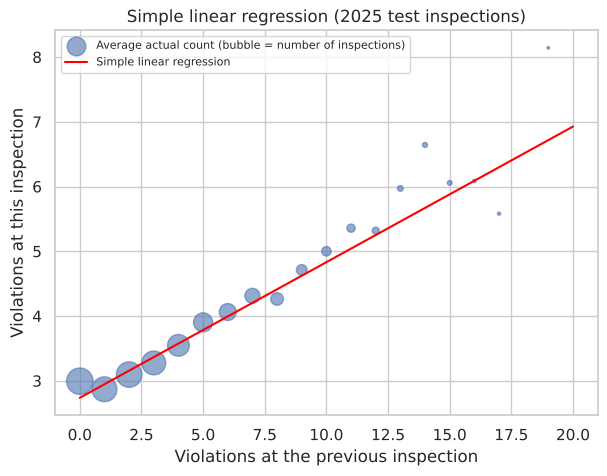

In [3]:
def make_encoder(cat, num):
    return ColumnTransformer([("cat", OneHotEncoder(drop="first", handle_unknown="infrequent_if_exist", min_frequency=100, sparse_output=False), cat), ("num", "passthrough", num)])

def metrics(name, y, pred):
    mse = mean_squared_error(y, pred)
    return {"Model": name, "Rows": len(y), "MAE": mean_absolute_error(y, pred), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y, pred)}

y_tr, y_te = train["violation_count"].values, test["violation_count"].values
baseline = metrics("Baseline: predict the training mean", y_te, np.full(len(y_te), y_tr.mean()))

# ---- 1. Simple linear regression: one meaningful predictor = PriorViolationCount (only inspections that HAVE a prior inspection)
tr_p, te_p = train[train["prior_inspection_result"] != "None"], test[test["prior_inspection_result"] != "None"]
simple = LinearRegression().fit(tr_p[["prior_violation_count"]], tr_p["violation_count"])
print("Simple linear regression: ViolationCount = %.3f + %.3f x PriorViolationCount   (trained on %d inspections with a prior inspection)" % (simple.intercept_, simple.coef_[0], len(tr_p)))
base_p = metrics("Baseline (training mean), inspections with a prior", te_p["violation_count"], np.full(len(te_p), tr_p["violation_count"].mean()))
res_simple = metrics("Simple LR: PriorViolationCount", te_p["violation_count"], simple.predict(te_p[["prior_violation_count"]]))
train_simple = metrics("Simple LR (train)", tr_p["violation_count"], simple.predict(tr_p[["prior_violation_count"]]))

plt.figure(figsize=(7, 5))
g = te_p.groupby("prior_violation_count")["violation_count"].agg(["mean", "count"]); g = g[g["count"] >= 20]
plt.scatter(g.index, g["mean"], s=g["count"] / 6, alpha=0.6, label="Average actual count (bubble = number of inspections)")
xs = np.arange(0, 21); plt.plot(xs, simple.predict(pd.DataFrame({"prior_violation_count": xs})), color="red", label="Simple linear regression")
plt.xlabel("Violations at the previous inspection"); plt.ylabel("Violations at this inspection"); plt.title("Simple linear regression (2025 test inspections)"); plt.legend(fontsize=8); plt.show()

In [4]:
# ---- 2. Multiple linear regression: all predictors
enc = make_encoder(CAT, NUM)
X_tr = enc.fit_transform(train[CAT + NUM]); X_te = enc.transform(test[CAT + NUM])
names = list(enc.get_feature_names_out())
multi = LinearRegression().fit(X_tr, y_tr)
pred_tr, pred_te = multi.predict(X_tr), multi.predict(X_te)
mask_p = (test["prior_inspection_result"] != "None").values
rows = [baseline, base_p, res_simple, metrics("Multiple LR: all test inspections", y_te, pred_te),
        metrics("Multiple LR: test inspections with a prior", y_te[mask_p], pred_te[mask_p]), metrics("Multiple LR (train, 2022-2024)", y_tr, pred_tr), train_simple]
results = pd.DataFrame(rows).set_index("Model")
print("Number of encoded features in the multiple model:", X_tr.shape[1])
results.to_csv("../results/regression_metrics.csv")
results.round(3)

/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0, 5] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Number of encoded features in the multiple model: 102


,Rows,MAE,MSE,RMSE,R2
Model,,,,,
Baseline: predict the training mean,15919,2.713,12.286,3.505,-0.007
"Baseline (training mean), inspections with a prior",13983,2.642,11.951,3.457,-0.000
Simple LR: PriorViolationCount,13983,2.499,11.313,3.363,0.053
Multiple LR: all test inspections,15919,2.447,10.730,3.276,0.121
Multiple LR: test inspections with a prior,13983,2.407,10.415,3.227,0.128
"Multiple LR (train, 2022-2024)",45266,2.414,10.703,3.272,0.248
Simple LR (train),30436,2.611,12.458,3.530,0.054


**Inference (model results):**
- **Design:** the models were trained on 45,266 inspections from 2022-2024 and tested on the 15,919 inspections of 2025 (chronological split, no shuffling).
- **Baseline:** always predicting the training mean (3.85) gives MAE 2.713, RMSE 3.505 and R² ≈ 0 on the test year.
- **Simple linear regression:** ViolationCount = 2.737 + 0.209 x PriorViolationCount. One more violation at the previous visit adds only 0.21 violations to the expectation. On the 13,983 test inspections that have a prior inspection it reaches R² = 0.053 and MAE 2.50 (baseline 2.64), so a facility's last count is a weak but real signal.
- **Multiple linear regression** (102 encoded features): test R² = **0.121**, MAE **2.447**, RMSE **3.276**. That is about 10% lower MAE and 6.5% lower RMSE than the baseline. On inspections with a prior inspection R² is 0.128.
- **Overfitting and drift:** training R² (0.248) is twice the test R² (0.121). Two reasons are visible in the data: the model has 102 features, many of them ZIP and facility-type dummies, and 2025 differs from the training years (mean violations 3.56 against 3.85, and 87.8% of the 2025 inspections have a prior inspection against 67.2% in training, because the history only starts in 2022).
- **Limit of OLS:** it predicted a negative violation count for 304 of the 15,919 test inspections (1.9%), which is impossible for a count.

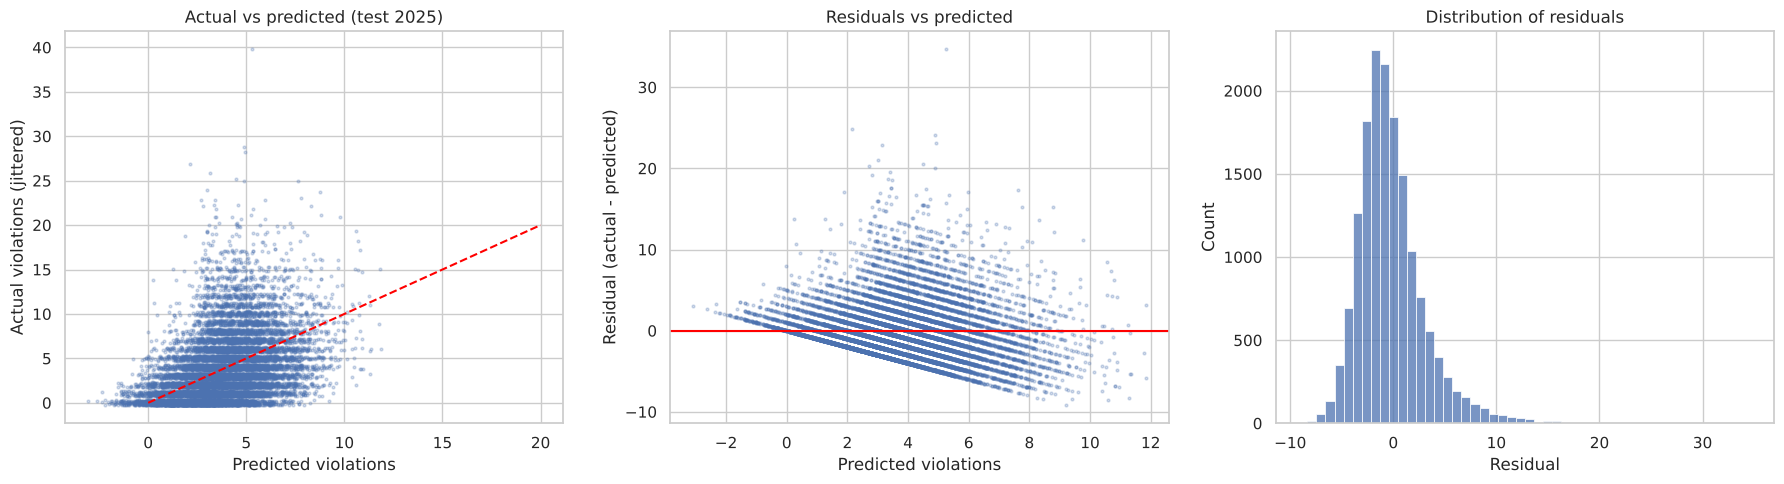

Residual mean -0.233 | std 3.267 | skewness 1.42


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
resid = y_te - pred_te
ax[0].scatter(pred_te, y_te + np.random.default_rng(0).uniform(-0.3, 0.3, len(y_te)), s=4, alpha=0.25)
ax[0].plot([0, 20], [0, 20], color="red", ls="--"); ax[0].set_xlabel("Predicted violations"); ax[0].set_ylabel("Actual violations (jittered)"); ax[0].set_title("Actual vs predicted (test 2025)")
ax[1].scatter(pred_te, resid, s=4, alpha=0.25); ax[1].axhline(0, color="red"); ax[1].set_xlabel("Predicted violations"); ax[1].set_ylabel("Residual (actual - predicted)"); ax[1].set_title("Residuals vs predicted")
sns.histplot(resid, bins=50, ax=ax[2], color="#4C72B0"); ax[2].set_title("Distribution of residuals"); ax[2].set_xlabel("Residual")
plt.tight_layout(); plt.show()
print("Residual mean %.3f | std %.3f | skewness %.2f" % (resid.mean(), resid.std(), pd.Series(resid).skew()))

Multiple linear regression: intercept = 2.302

Largest effects (change in expected violations versus the reference category):


,feature,coefficient
0,cat__zip_60617,4.597
1,cat__zip_60633,4.543
2,cat__zip_60620,4.533
3,cat__facility_type_Shared Kitchen User (Long T...,-3.910
4,cat__zip_60636,3.881
5,cat__zip_60628,3.761
6,cat__zip_infrequent_sklearn,3.505
7,cat__zip_60660,3.157
8,cat__facility_type_Golden Diner,-3.108
9,cat__zip_60651,3.090


Prior-history and risk coefficients:


,feature,coefficient
0,cat__inspection_type_License Re-Inspection,-2.370
1,cat__inspection_type_Complaint Re-Inspection,-2.356
2,cat__risk_category_Risk 3 (Low),-1.326
3,cat__risk_category_infrequent_sklearn,-1.321
4,cat__prior_inspection_result_None,1.262
5,cat__inspection_type_Complaint,1.240
6,cat__inspection_type_License,-0.863
7,cat__risk_category_Risk 2 (Medium),-0.775
8,cat__prior_inspection_result_Fail,-0.557
9,num__prior_violation_count,0.263


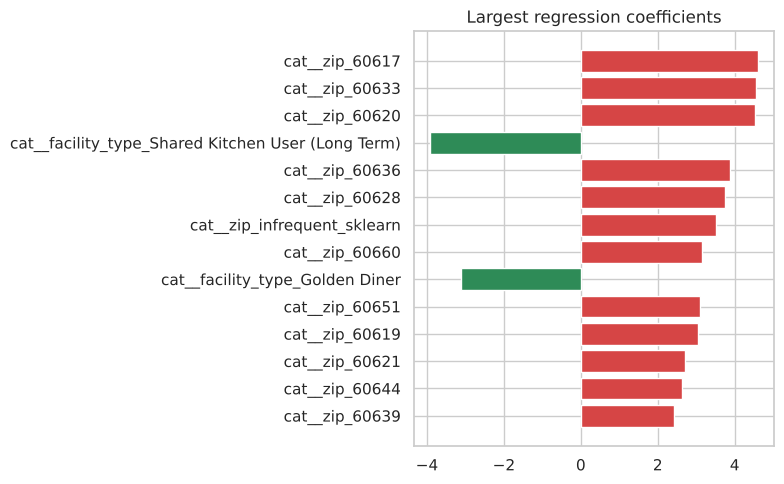

In [6]:
coef = pd.DataFrame({"feature": names, "coefficient": multi.coef_})
coef["abs"] = coef["coefficient"].abs()
coef.sort_values("abs", ascending=False).head(15)[["feature", "coefficient"]].to_csv("../results/regression_top_coefficients.csv", index=False)
print("Multiple linear regression: intercept = %.3f" % multi.intercept_)
print("\nLargest effects (change in expected violations versus the reference category):")
display(coef.sort_values("abs", ascending=False).head(14)[["feature", "coefficient"]].round(3).reset_index(drop=True))
print("Prior-history and risk coefficients:")
display(coef[coef["feature"].str.contains("prior|risk|inspection_type_Complaint|inspection_type_License")].sort_values("abs", ascending=False).head(10)[["feature", "coefficient"]].round(3).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(8, 5)); top = coef.sort_values("abs", ascending=False).head(14)[::-1]
ax.barh(top["feature"], top["coefficient"], color=["#d64545" if v > 0 else "#2e8b57" for v in top["coefficient"]]); ax.set_title("Largest regression coefficients"); plt.tight_layout(); plt.show()

**Inference (regression coefficients):** the reference categories are the first level of each feature (for example Risk 1 (High), the Canvass inspection type and a prior result of Conditional Pass), so a coefficient is the change in the expected number of violations compared with that reference, with the other features fixed.
- **Location matters most.** Inspections in ZIP codes 60617, 60633 and 60620 record about 4.5 more violations than the reference ZIP, and 60636 and 60628 about 3.8. The rare-ZIP group has +3.5. A very few types go the other way: Shared Kitchen User (Long Term) -3.9 and Golden Diner -3.1.
- **Inspection type:** re-inspections have about 2.4 fewer violations (License Re-Inspection -2.37, Complaint Re-Inspection -2.36), because the problems were already found at the previous visit. Complaint inspections have 1.2 more than a routine canvass.
- **Risk:** Risk 3 (Low) facilities record 1.3 fewer violations than Risk 1 (High) ones, and Risk 2 about 0.8 fewer.
- **History:** every violation at the previous inspection adds 0.26 violations in the multiple model. A facility with no earlier inspection in the data has 1.26 more than one whose previous result was a conditional pass.
- These are associations in 2022-2024, not causes. Coefficients of rare dummies (at least 100 rows each) are less certain than those of common categories.

## 3. Regression diagnostics

In [7]:
# ---- multicollinearity (variance inflation factor) on the training design matrix
Xd = pd.DataFrame(X_tr, columns=names)
Xd = Xd.loc[:, Xd.std() > 0]
Xc = sm.add_constant(Xd, has_constant="add")
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=Xd.columns).sort_values(ascending=False)
print("Highest variance inflation factors (VIF > 5 suggests collinearity; > 10 is serious):")
display(vif.head(8).round(2).to_frame("VIF"))
print("Number of features with VIF > 5: %d of %d" % ((vif > 5).sum(), len(vif)))

# ---- heteroscedasticity: Breusch-Pagan test on the training residuals
ols = sm.OLS(y_tr, Xc).fit()
lm, lm_p, fval, f_p = het_breuschpagan(ols.resid, Xc)
print("\nBreusch-Pagan test for heteroscedasticity: LM = %.1f, p-value = %.2e" % (lm, lm_p))
bins = pd.qcut(pd.Series(pred_te), 5, duplicates="drop")
spread = pd.DataFrame({"fitted_quintile": bins, "residual": resid}).groupby("fitted_quintile", observed=True)["residual"].agg(["count", "mean", "std"]).round(3)
display(spread)

Highest variance inflation factors (VIF > 5 suggests collinearity; > 10 is serious):


,VIF
cat__facility_type_Restaurant,16.59
cat__prior_inspection_result_Fail,10.32
cat__facility_type_Grocery Store,7.76
cat__inspection_type_Canvass Re-Inspection,7.72
cat__facility_type_School,6.40
cat__prior_inspection_result_None,4.13
cat__facility_type_Children's Services Facility,3.96
cat__inspection_type_Complaint Re-Inspection,3.62


Number of features with VIF > 5: 5 of 102



Breusch-Pagan test for heteroscedasticity: LM = 3502.1, p-value = 0.00e+00


,count,mean,std
fitted_quintile,,,
"(-3.094, 2.307]",3184,0.305,2.051
"(2.307, 3.298]",3184,-0.015,3.103
"(3.298, 4.171]",3183,-0.076,3.282
"(4.171, 5.243]",3184,-0.265,3.640
"(5.243, 11.844]",3184,-1.115,3.794


In [8]:
# ---- outliers: how much do extreme counts matter?
q1, q3 = np.percentile(y_tr, [25, 75]); fence = q3 + 1.5 * (q3 - q1)
ext = y_te > fence
print("Outlier fence (Q3 + 1.5 x IQR) = %.0f violations; %.1f%% of 2025 inspections are above it" % (fence, 100 * ext.mean()))
print("Test RMSE: all inspections %.3f | without the outliers %.3f" % (np.sqrt(mean_squared_error(y_te, pred_te)), np.sqrt(mean_squared_error(y_te[~ext], pred_te[~ext]))))
print("Share of the total squared error that comes from the outliers: %.1f%%" % (100 * (resid[ext] ** 2).sum() / (resid ** 2).sum()))
# sensitivity: train on a target capped at the 99th percentile
cap = np.percentile(y_tr, 99)
capped = LinearRegression().fit(X_tr, np.minimum(y_tr, cap))
print("Model trained on a capped target (cap = %.0f): test MAE %.3f, RMSE %.3f, R2 %.3f  (uncapped: MAE %.3f, RMSE %.3f, R2 %.3f)" % (
      cap, mean_absolute_error(y_te, capped.predict(X_te)), np.sqrt(mean_squared_error(y_te, capped.predict(X_te))), r2_score(y_te, capped.predict(X_te)),
      mean_absolute_error(y_te, pred_te), np.sqrt(mean_squared_error(y_te, pred_te)), r2_score(y_te, pred_te)))
print("\nNegative predictions on the test data: %d of %d" % ((pred_te < 0).sum(), len(pred_te)))

Outlier fence (Q3 + 1.5 x IQR) = 14 violations; 1.9% of 2025 inspections are above it
Test RMSE: all inspections 3.276 | without the outliers 2.865
Share of the total squared error that comes from the outliers: 24.9%


Model trained on a capped target (cap = 17): test MAE 2.432, RMSE 3.261, R2 0.128  (uncapped: MAE 2.447, RMSE 3.276, R2 0.121)

Negative predictions on the test data: 304 of 15919


**Inference (diagnostics):**
- **Multicollinearity:** only 5 of the 102 features have a VIF above 5: Restaurant (16.6), prior result Fail (10.3), Grocery Store (7.8), Canvass Re-Inspection (7.7) and School (6.4). Restaurant is 70% of all rows, so its dummy is naturally correlated with the others. No feature is perfectly collinear (the redundant `has_prior_inspection` flag was left out). Collinearity makes the individual coefficients less stable but does not hurt the predictions.
- **Heteroscedasticity:** the Breusch-Pagan test is highly significant (LM = 3,502, p < 0.001). The spread of the residuals grows with the predicted value: the standard deviation is 2.05 in the lowest fifth of the predictions and 3.79 in the highest fifth. In the highest fifth the mean residual is -1.1, so the model over-predicts the inspections it expects to be bad. The usual OLS confidence intervals would be unreliable here.
- **Residuals:** mean -0.23, standard deviation 3.27 and skewness 1.42. They are right-skewed because a few inspections have many more violations than predicted.
- **Outliers:** only 1.9% of the 2025 inspections have more than 14 violations (the training Q3 + 1.5 x IQR), but they cause 24.9% of the total squared error; RMSE falls from 3.276 to 2.865 without them. Training on a target capped at 17 violations changes the test R² only from 0.121 to 0.128, so the result is not very sensitive to the extreme counts.

## Conclusion and limitations
1. The number of violations is **hard to predict from information known before the inspection**: the best model explains about 12% of the variation in the test year (R² 0.121, MAE 2.45 against 2.71 for the baseline).
2. The signals that help are **where** the facility is (ZIP), **what kind** of inspection it is (re-inspections have far fewer violations, complaints more), the facility's **risk category** and its **previous violation count**.
3. **Data leakage was avoided:** the result, violation band and failure flag of the current inspection were not used, and the prior-history features use only earlier inspections. The split is chronological.
4. **Limitations:** OLS is not an ideal model for a count (negative predictions, non-constant variance); a Poisson or negative-binomial model would be the next step. The history is cut at January 2022, 2025 behaves differently from 2022-2024, and important causes (kitchen size, staff training, equipment) are not in the data. The model is too weak to schedule inspections on its own; it can only support screening together with other information.